In [1]:
!pip install qiskit qiskit-aer matplotlib pylatexenc

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Circuit A: X gate, then measure
qc_a = QuantumCircuit(1, 1)   # 1 qubit starts in |0>
qc_a.x(0)
qc_a.measure(0, 0)

# Circuit B: two X gates, then measure
qc_b = QuantumCircuit(1, 1)
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)

# Circuit C: H gate, then measure
qc_c = QuantumCircuit(1, 1)
qc_c.h(0)
qc_c.measure(0, 0)

print("Circuit A"); print(qc_a.draw())
print("Circuit B"); print(qc_b.draw())
print("Circuit C"); print(qc_c.draw())

Circuit A
     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Circuit B
     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 
Circuit C
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [4]:
print("PREDICTIONS (before running)")
print("-" * 50)
print("Circuit A (X gate):")
print("  X flips |0> to |1>, so I expect '1' in all 100 shots.\n")

print("Circuit B (X, X gates):")
print("  The second X flips the qubit back to |0>, so I expect '0' in all 100 shots.\n")

print("Circuit C (H gate):")
print("  H puts the qubit in an equal superposition, so I expect about 50% '0' and 50% '1' (roughly 50/50, not exactly).\n")

print("Will Circuit C always give the same result?")
print("  No. Each measurement is random, and only the overall distribution is predictable.")

PREDICTIONS (before running)
--------------------------------------------------
Circuit A (X gate):
  X flips |0> to |1>, so I expect '1' in all 100 shots.

Circuit B (X, X gates):
  The second X flips the qubit back to |0>, so I expect '0' in all 100 shots.

Circuit C (H gate):
  H puts the qubit in an equal superposition, so I expect about 50% '0' and 50% '1' (roughly 50/50, not exactly).

Will Circuit C always give the same result?
  No. Each measurement is random, and only the overall distribution is predictable.


In [5]:
sim = AerSimulator()
shots = 100

def run_circuit(qc):
    compiled = transpile(qc, sim)
    result = sim.run(compiled, shots=shots).result()
    return result.get_counts()

counts_a = run_circuit(qc_a)
counts_b = run_circuit(qc_b)
counts_c = run_circuit(qc_c)

print("Circuit A results:", counts_a)
print("Circuit B results:", counts_b)
print("Circuit C results:", counts_c)

Circuit A results: {'1': 100}
Circuit B results: {'0': 100}
Circuit C results: {'0': 46, '1': 54}


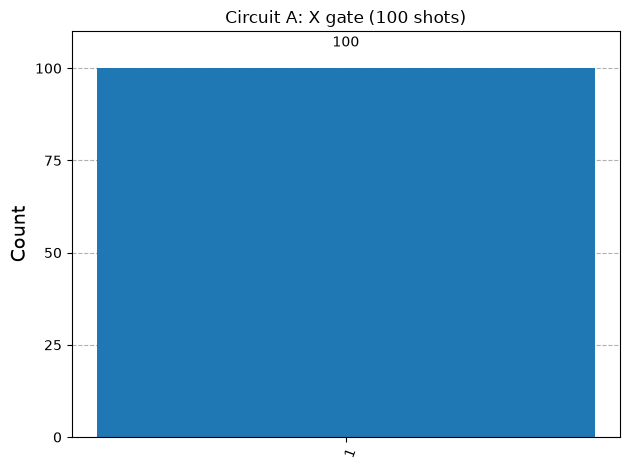

In [6]:
plot_histogram(counts_a, title="Circuit A: X gate (100 shots)")

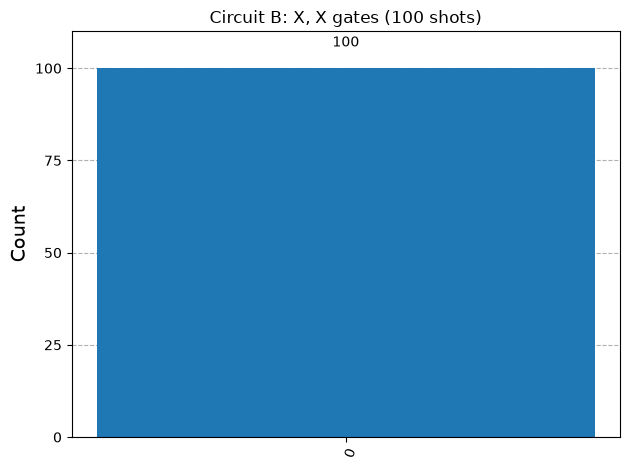

In [7]:
plot_histogram(counts_b, title="Circuit B: X, X gates (100 shots)")

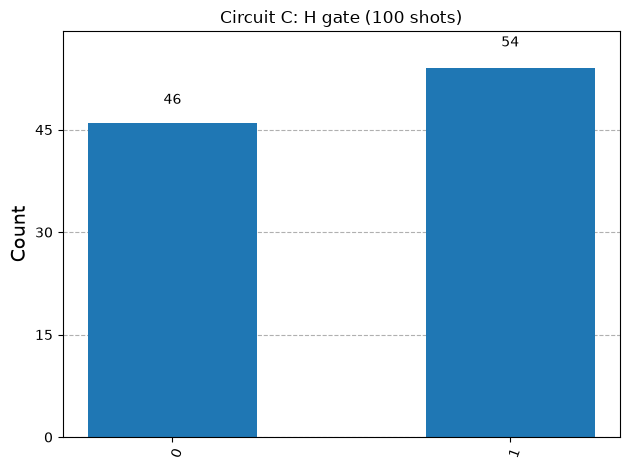

In [8]:
plot_histogram(counts_c, title="Circuit C: H gate (100 shots)")

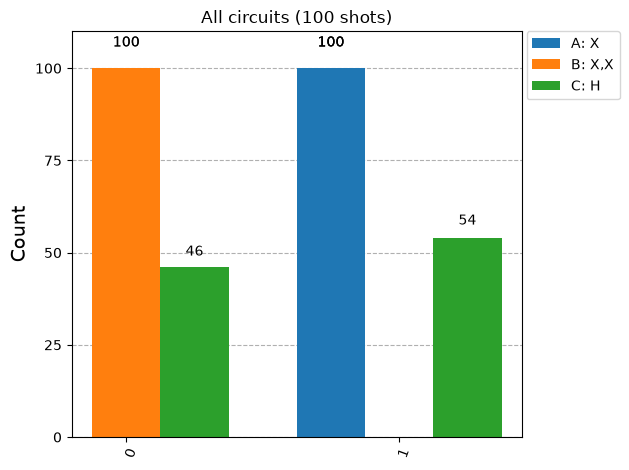

In [9]:
plot_histogram([counts_a, counts_b, counts_c],
               legend=["A: X", "B: X,X", "C: H"],
               title="All circuits (100 shots)")

In [10]:
print("COMPARISON: PREDICTIONS vs ACTUAL RESULTS")
print("-" * 60)
print(f"Circuit A (X)    | Predicted: 100% '1'      | Actual: {counts_a}")
print(f"Circuit B (X, X) | Predicted: 100% '0'      | Actual: {counts_b}")
print(f"Circuit C (H)    | Predicted: ~50% / ~50%   | Actual: {counts_c}")

print("\nConclusion:")
print("Circuits A and B matched my predictions exactly: X flips the qubit, and two X gates cancel out.")
print("Circuit C came out close to 50/50 but not exactly, because the H gate creates a superposition")
print("and each shot is random. Running it again will give slightly different counts.")

COMPARISON: PREDICTIONS vs ACTUAL RESULTS
------------------------------------------------------------
Circuit A (X)    | Predicted: 100% '1'      | Actual: {'1': 100}
Circuit B (X, X) | Predicted: 100% '0'      | Actual: {'0': 100}
Circuit C (H)    | Predicted: ~50% / ~50%   | Actual: {'0': 46, '1': 54}

Conclusion:
Circuits A and B matched my predictions exactly: X flips the qubit, and two X gates cancel out.
Circuit C came out close to 50/50 but not exactly, because the H gate creates a superposition
and each shot is random. Running it again will give slightly different counts.
